In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,confusion_matrix

In [4]:
df=pd.read_csv('Purchase_Logistic.csv')

In [5]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


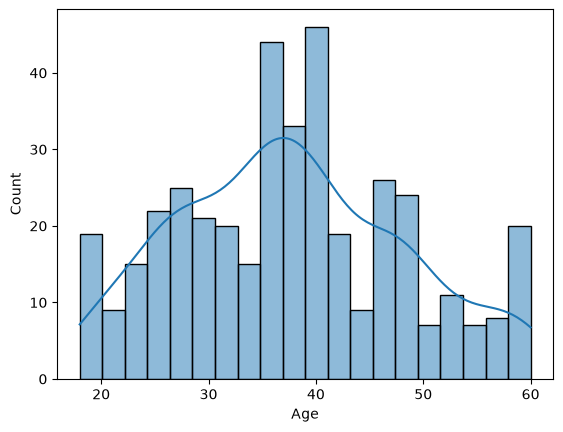

In [59]:
sns.histplot(
    df["Age"],
    bins=20,
    kde=True
)

plt.show()

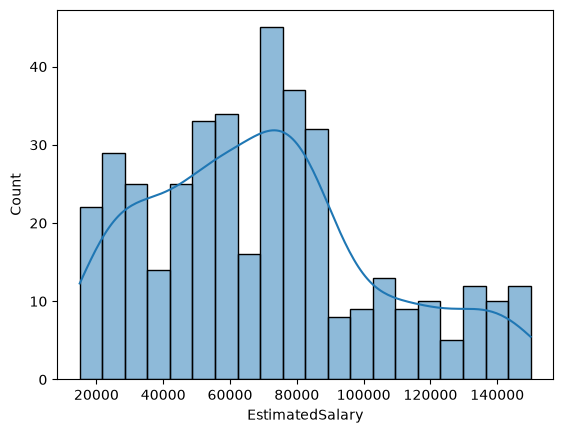

In [60]:
sns.histplot(
    df["EstimatedSalary"],
    bins=20,
    kde=True
)

plt.show()

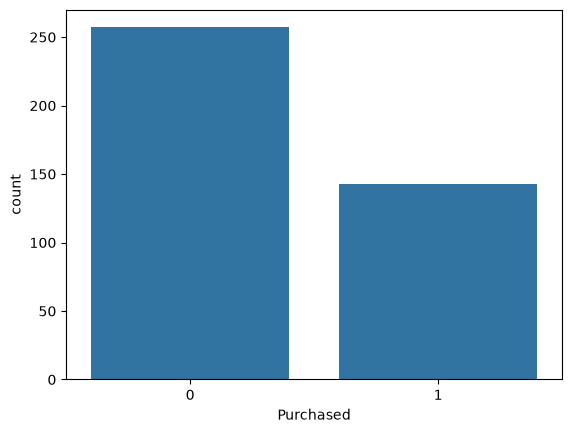

In [58]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(
    x="Purchased",
    data=df
)

plt.show()

<BarContainer object of 400 artists>

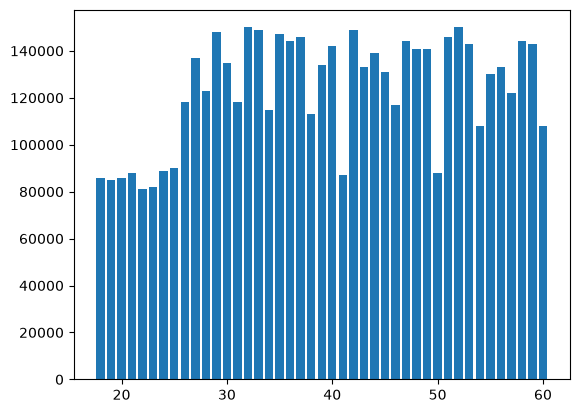

In [56]:
plt.bar(df['Age'],df['EstimatedSalary'])

In [8]:
from sklearn.preprocessing import LabelEncoder

In [9]:
lb=LabelEncoder()

In [10]:
df['Gender']=lb.fit_transform(df['Gender'])

In [11]:
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,1,19,19000,0
1,15810944,1,35,20000,0
2,15668575,0,26,43000,0
3,15603246,0,27,57000,0
4,15804002,1,19,76000,0
...,...,...,...,...,...
395,15691863,0,46,41000,1
396,15706071,1,51,23000,1
397,15654296,0,50,20000,1
398,15755018,1,36,33000,0


In [12]:
from sklearn.preprocessing import StandardScaler

In [15]:
xx=df[['Gender','Age','EstimatedSalary']]
y=df['Purchased']

In [19]:
scaler = StandardScaler()

In [21]:
x=scaler.fit_transform(xx)

In [22]:
print(x)

[[ 1.02020406 -1.78179743 -1.49004624]
 [ 1.02020406 -0.25358736 -1.46068138]
 [-0.98019606 -1.11320552 -0.78528968]
 ...
 [-0.98019606  1.17910958 -1.46068138]
 [ 1.02020406 -0.15807423 -1.07893824]
 [-0.98019606  1.08359645 -0.99084367]]


In [23]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [27]:
model=LogisticRegression()

In [28]:
model.fit(x,y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [29]:
y_pred=model.predict(x_test)

In [38]:
import pandas as pd

new_data = pd.DataFrame({
    "Gender": [1, 0, 1, 0, 1],
    "Age": [10, 25, 45, 32, 50],
    "EstimatedSalary": [200, 35000, 120000, 60000, 150000]
})

print(new_data)

   Gender  Age  EstimatedSalary
0       1   10              200
1       0   25            35000
2       1   45           120000
3       0   32            60000
4       1   50           150000


In [40]:
new_data_scaled = scaler.transform(new_data)

model.predict(new_data_scaled)

array([0, 0, 1, 0, 1])

In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    log_loss
)


y_pred = model.predict(x_test)

y_prob = model.predict_proba(x_test)[:,1]


print("Accuracy:",
      accuracy_score(y_test,y_pred))


print("Precision:",
      precision_score(y_test,y_pred))


print("Recall:",
      recall_score(y_test,y_pred))


print("F1:",
      f1_score(y_test,y_pred))


print("ROC-AUC:",
      roc_auc_score(y_test,y_prob))


print("Log Loss:",
      log_loss(y_test,y_prob))


print(
classification_report(
    y_test,
    y_pred
)
)


print(
confusion_matrix(
    y_test,
    y_pred
)
)

Accuracy: 0.9
Precision: 0.9166666666666666
Recall: 0.7857142857142857
F1: 0.8461538461538461
ROC-AUC: 0.9725274725274724
Log Loss: 0.2388262100371378
              precision    recall  f1-score   support

           0       0.89      0.96      0.93        52
           1       0.92      0.79      0.85        28

    accuracy                           0.90        80
   macro avg       0.90      0.87      0.89        80
weighted avg       0.90      0.90      0.90        80

[[50  2]
 [ 6 22]]
